## Initialization

#### Import Library, find available devices

In [2]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import glob
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict
from scipy.optimize import curve_fit

## Data

<Figure size 640x480 with 0 Axes>

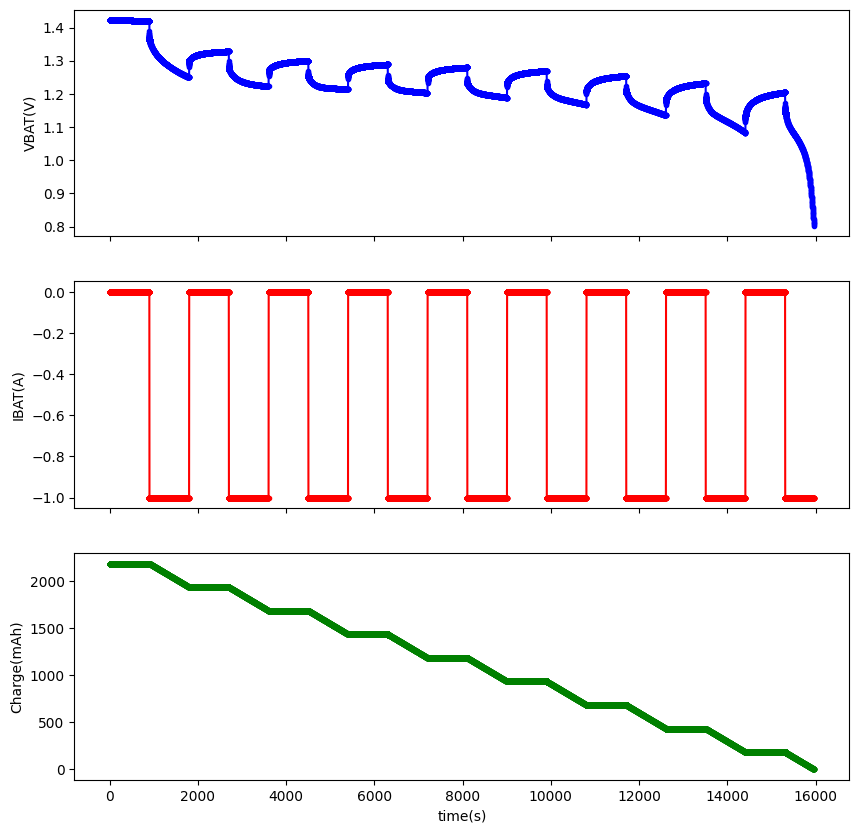

In [16]:
df = pd.read_csv("Discharging_2_truncated/complete.csv")
DOD = df["DOD"]
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')

lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(df["times"], df["voltage"])
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(df["times"], df["current"])
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(df["times"], Charge)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()
display(fig)
clear_output(wait = True)

<Figure size 640x480 with 0 Axes>

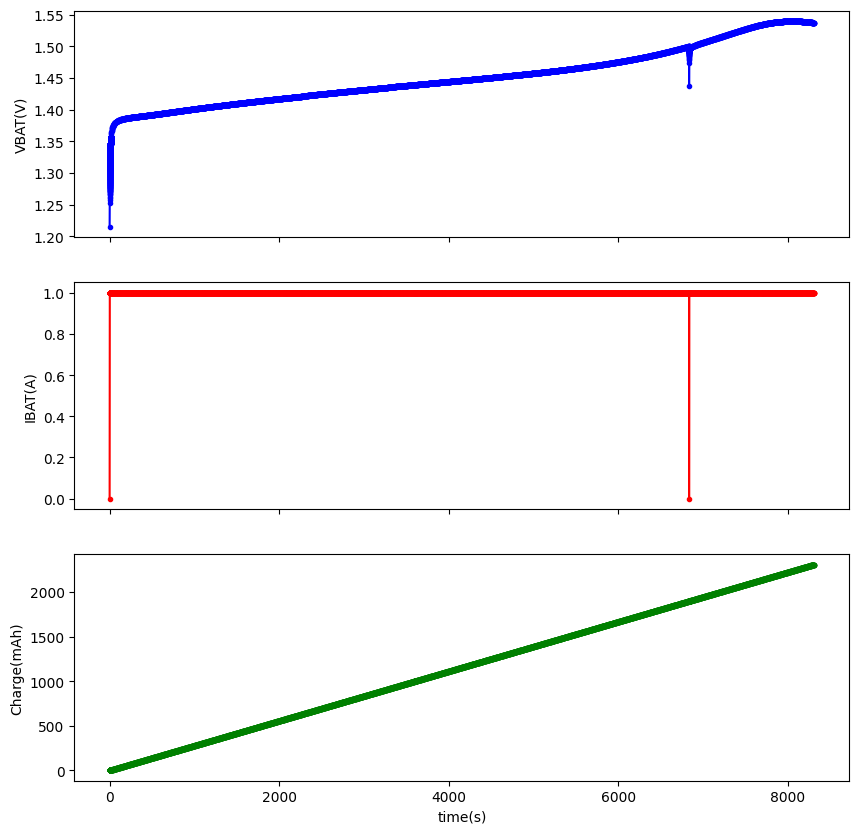

In [ ]:
df = pd.read_csv("Charging_1/complete.csv")
df2 = pd.read_csv("Charging/complete.csv")
DOD = np.concatenate((df["DOD"], df2["DOD"]+df["DOD"][len(df)-1]))
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')
times_combined= np.concatenate((df["times"], df2["times"]+df["times"][len(df)-1]))
voltage_combined = np.concatenate((df["voltage"], df2["voltage"]))
current_combined = np.concatenate((df["current"], df2["current"]))



lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(times_combined, voltage_combined)
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(times_combined, current_combined)
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(times_combined, DOD)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()
display(fig)
clear_output(wait = True)

save_dir = "Charging_combined"
os.makedirs(save_dir, exist_ok=True)
df = pd.DataFrame({'times': times_combined, 'voltage': voltage_combined, 'current': current_combined, 'DOD':DOD})
df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)

SOC=0.00, R0= 1.00 Ω, R1= -0.03 Ω, R2= -0.03 Ω, C1= -4274.24 F, C2= -50043.41 F, OCV= 1.42 V


C:\Users\lskarda\AppData\Local\Temp\ipykernel_30364\2075566560.py:89: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


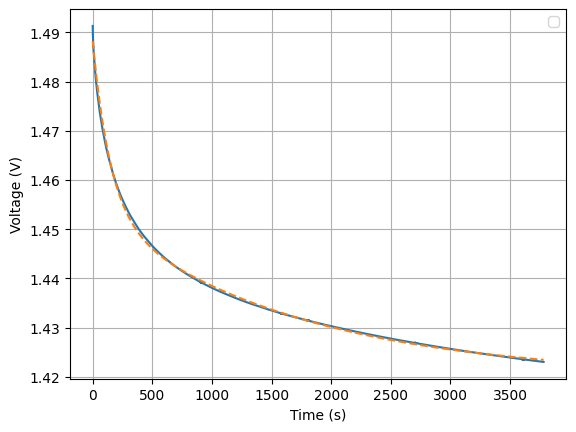

In [ ]:
folder_path = "charged_roll_off"

# 2. Get a list of all CSV files in that folder
# The asterisk (*) is a wildcard that matches any filename
file_pattern = os.path.join(folder_path, "SOC*.csv")
file_list = glob.glob(file_pattern)
file_list.sort(key=lambda f: float(os.path.basename(f).replace("SOC=", "").replace(".csv", "")))
for file in file_list:
    df = pd.read_csv(file)
    times1 = df["times"]
    VBAT1 = df["voltage"]
    IBAT1 = df["current"]
    DOD1 = df["DOD"]
    IBAT1=IBAT1.values.tolist()
    #VBAT1=VBAT1.values.tolist()

    """ For the final curve in the discharge. It wasn't saved properly
    index=32505
    VBAT2= VBAT1.values.tolist()[index:]
    IBAT2= IBAT1[index:]
    DOD2= DOD1[index:]
    times2= times1[index:]
    index2 = IBAT2.index(-1)
    VBAT= VBAT2[:index2]
    IBAT= IBAT2[:index2]
    DOD= DOD2[:index2]
    times= times2[:index2]
    times = times - times[index]
    """

    index = IBAT1.index(-1)
    #index= len(IBAT1)
    VBAT= VBAT1.values.tolist()[20:index]
    IBAT= IBAT1[20:index]
    DOD= DOD1[:index]
    OCV= VBAT[-1]
    R0 =  1 #(VBAT1[index+20] - VBAT[-1]) / IBAT1[index]
    times= times1[20:index]
    #index= len(IBAT)
    times = times - times[20]

    ### Curve Fitting ###

    def double_exp(t, A, B1, tau1, B2, tau2):
        return A + B1*np.exp(-t/tau1) + B2*np.exp(-t/tau2)


    A0 = VBAT[-1]                  # final voltage
    B1_0 = VBAT[0] - VBAT[-1]        # initial drop
    B2_0 = 0.1 * B1_0

    tau1_0 = 1
    tau2_0 = 50

    p0 = [A0, B1_0, tau1_0, B2_0, tau2_0]



    popt, pcov = curve_fit(double_exp, times, VBAT, p0=p0, maxfev=10000)

    A, B1, tau1, B2, tau2 = popt


    I = 1.0

    R1 = -B1 / I
    R2 = -B2 / I

    # time constants
    # tau = R * C → C = tau / R

    C1 = tau1 / R1
    C2 = tau2 / R2
    print(f"SOC={df['SOC'][0]:.2f}, R0= {R0:.2f} Ω, R1= {R1:.2f} Ω, R2= {R2:.2f} Ω, C1= {C1:.2f} F, C2= {C2:.2f} F, OCV= {OCV:.2f} V")

    file_name = folder_path+"/BAT_ECM_Discharge2.csv"
    data= [[round(df["SOC"][0],3), round(R0,5), round(R1,5), round(R2,5), int(C1), int(C2), round(OCV,3)]]
    df_new = pd.DataFrame(data, columns=["SOC", "R0", "R1", "R2", "C1", "C2", "OCV"])
    file_exists = os.path.isfile(file_name)
    df_new.to_csv(file_name, mode='a', index=False, header=not file_exists)


    v_fit = double_exp(times, *popt)

    plt.plot(times, VBAT) #label=f"Measured_SOC={df["SOC"][0]:.2f}")
    plt.plot(times, v_fit, '--') #label=f"Fit_SOC={df["SOC"][0]:.2f}")
plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.legend()
plt.grid()
plt.show()



